# Домашнее задание 1: часть A (VAE)

В этом ноутбуке вы реализуете **VAE для лиц**: обучение, реконструкция и редактирование эмоций (улыбка → грусть) через латентное пространство. StyleGAN-подобная модель — в ноутбуке `HW_1_part_B.ipynb`.

В домашнем задании:

- Модели должны быть реализованы самостоятельно (свои классы в PyTorch, без использования готовых реализаций из репозиториев).
- Результаты обучения (лоссы, изображения) необходимо логировать в **TensorBoard** (`torch.utils.tensorboard.SummaryWriter`).
- Ноутбук сдаётся **с выполненными ячейками**: должны быть видны выводы, графики и картинки.

**Эксперимент.** Собственная свёрточная VAE, RGB 64×64, `latent_dim=128`, полный официальный train/valid/test CelebA. Обучение с нуля, 30 эпох, Adam, cosine learning rate и прогрев KL за первые 5 эпох. Обе части loss суммируются по признакам и усредняются по батчу. Лучшая модель выбирается по validation loss при `beta=1`; test используется после выбора модели. Разрешение 64×64 сокращает время эксперимента и разрешено шаблоном. Датасет и пакеты на сервере переиспользуются по ссылкам; файлы других проектов не изменяются.


### Часть A. Шаг 1: Импорт библиотек, настройка окружения и TensorBoard

Что сделать: импортировать необходимые библиотеки, настроить устройство (CPU/GPU), создать `SummaryWriter` для логирования обучения VAE.

Ожидается: корректная инициализация окружения и путь к логам TensorBoard для VAE.

In [1]:
import os, math, json, random, time, platform
from pathlib import Path
from datetime import datetime
import numpy as np
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim
from torch.utils.data import DataLoader, Dataset, Subset
from torchvision import transforms
from torchvision.utils import make_grid, save_image
from torch.utils.tensorboard import SummaryWriter

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.cuda.manual_seed_all(SEED)
torch.set_num_threads(8)
torch.backends.cudnn.benchmark = True
# Seed фиксирует генераторы; быстрые CUDA-алгоритмы не гарантируют побитовое повторение.
device = torch.device('cuda:0' if torch.cuda.is_available() else 'cpu')
for folder in ['runs', 'checkpoints', 'results', 'data/cache']:
    Path(folder).mkdir(parents=True, exist_ok=True)
run_name = datetime.now().strftime('vae_%Y%m%d_%H%M%S')
log_dir_vae = str(Path('runs') / run_name)
writer_vae = SummaryWriter(log_dir_vae)
print(f'Устройство: {device}; torch={torch.__version__}')
if device.type == 'cuda':
    print(torch.cuda.get_device_name(device))
print(f'TensorBoard VAE: {Path(log_dir_vae).resolve()}')


Устройство: cuda:0; torch=2.8.0+cu126


NVIDIA A100-SXM4-80GB
TensorBoard VAE: /home/edu/adpak/gen_cv/runs/vae_20261126_024037


### Часть A. Шаг 2: Загрузка и предобработка датасета лиц

Что сделать: задать трансформации (crop, resize, normalize), создать датасет CelebA и `DataLoader`.

**Где взять данные.** Нужна версия *Align&Cropped* (`img_align_celeba`, ~200 тыс. изображений 178×218) и файлы разметки. Источники: официальная страница https://mmlab.ie.cuhk.edu.hk/projects/CelebA.html или зеркало на Kaggle `jessicali9530/celeba-dataset`. Автоскачивание `torchvision.datasets.CelebA(download=True)` часто падает из-за лимитов Google Drive.

Положите всё в одну папку:

```
data/celeba/CelebA/
├── img_align_celeba/        # 000001.jpg, 000002.jpg, ...
├── list_attr_celeba.txt     # или list_attr_celeba.csv (Kaggle)
└── list_eval_partition.txt  # или list_eval_partition.csv (Kaggle)
```

Ниже дан готовый класс `CelebAWithAttrs`: он читает и `.txt`, и `.csv` и сам находит вложенную папку `img_align_celeba/img_align_celeba` из архива Kaggle. Датасет возвращает пары `(image, attrs)`, атрибуты приведены к значениям **{0, 1}** (в исходных файлах {−1, 1}). Также доступны `dataset.attr_names` (список из 40 имён) и `dataset.attr` (тензор `[N, 40]`). Последующие ячейки ноутбука рассчитаны именно на этот интерфейс.

Ожидается: корректный `DataLoader` с батчами `(images, attrs)`.

In [2]:
import csv
from pathlib import Path

from PIL import Image
from torch.utils.data import Dataset


class CelebAWithAttrs(Dataset):
    """CelebA (Align&Cropped) с атрибутами.

    root — папка, где лежат img_align_celeba/ и файлы разметки (.txt или .csv).
    split — 'train', 'valid', 'test' или 'all' (по list_eval_partition).
    Возвращает (image, attrs), attrs — float-тензор из 0 и 1 длины 40.
    """

    SPLITS = {"train": 0, "valid": 1, "test": 2}

    def __init__(self, root, split="train", transform=None):
        root = Path(root)
        self.transform = transform

        img_dir = root / "img_align_celeba"
        if (img_dir / "img_align_celeba").is_dir():  # архив с Kaggle
            img_dir = img_dir / "img_align_celeba"
        if not img_dir.is_dir():
            raise FileNotFoundError(f"Не найдена папка с изображениями: {img_dir}")
        self.img_dir = img_dir

        self.attr_names, attrs = self._read_attrs(root)
        partition = self._read_partition(root)

        if split == "all":
            files = list(attrs)
        else:
            files = [f for f in attrs if partition[f] == self.SPLITS[split]]
        self.filenames = files
        self.attr = torch.tensor([attrs[f] for f in files], dtype=torch.long)
        self.attr = (self.attr + 1) // 2  # {-1, 1} -> {0, 1}

    @staticmethod
    def _read_attrs(root):
        txt, csv_path = root / "list_attr_celeba.txt", root / "list_attr_celeba.csv"
        attrs = {}
        if txt.exists():
            with open(txt) as f:
                lines = f.read().splitlines()
            names = lines[1].split()
            for line in lines[2:]:
                parts = line.split()
                attrs[parts[0]] = [int(v) for v in parts[1:]]
        elif csv_path.exists():
            with open(csv_path) as f:
                reader = csv.reader(f)
                names = next(reader)[1:]
                for row in reader:
                    attrs[row[0]] = [int(v) for v in row[1:]]
        else:
            raise FileNotFoundError(f"Не найден list_attr_celeba.txt/.csv в {root}")
        return names, attrs

    @staticmethod
    def _read_partition(root):
        txt, csv_path = root / "list_eval_partition.txt", root / "list_eval_partition.csv"
        if txt.exists():
            with open(txt) as f:
                return {p[0]: int(p[1]) for p in (l.split() for l in f) if p}
        if csv_path.exists():
            with open(csv_path) as f:
                reader = csv.reader(f)
                next(reader)
                return {row[0]: int(row[1]) for row in reader}
        raise FileNotFoundError(f"Не найден list_eval_partition.txt/.csv в {root}")

    def __len__(self):
        return len(self.filenames)

    def __getitem__(self, idx):
        image = Image.open(self.img_dir / self.filenames[idx]).convert("RGB")
        if self.transform is not None:
            image = self.transform(image)
        return image, self.attr[idx].float()

Кэш создан: 202599 изображений, 19.4 с
train=162770, valid=19867, test=19962
Батчей train: 636, размер кадра: 64×64


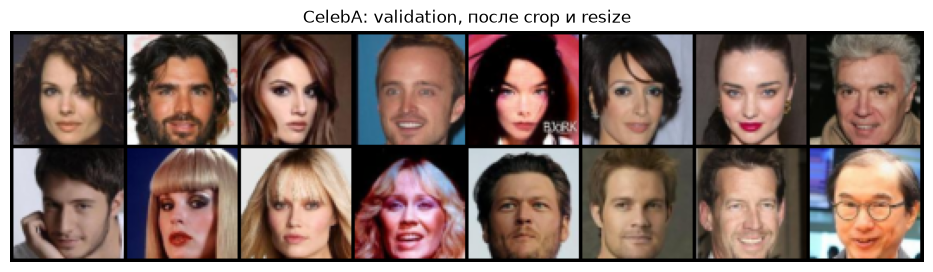

In [3]:
image_size = 64
batch_size = 256
root = Path(os.environ.get('CELEBA_ROOT', 'data/celeba/CelebA'))
# Один и тот же crop/resize для всех split; отражение применяется только при обучении.
transform = transforms.Compose([
    transforms.CenterCrop(140),
    transforms.Resize(image_size, antialias=True),
    transforms.ToTensor(),
    transforms.Normalize([0.5] * 3, [0.5] * 3),
])
base_train = CelebAWithAttrs(root, 'train', transform)
base_valid = CelebAWithAttrs(root, 'valid', transform)
base_test = CelebAWithAttrs(root, 'test', transform)
assert set(base_train.filenames).isdisjoint(base_valid.filenames)
assert set(base_train.filenames).isdisjoint(base_test.filenames)

# uint8-кэш ускоряет повторные эпохи, исходные JPEG не изменяются.
cache_path = Path(f'data/cache/celeba_crop140_{image_size}_uint8.npy')
all_faces = CelebAWithAttrs(root, 'all', transforms.Compose([
    transforms.CenterCrop(140), transforms.Resize(image_size, antialias=True),
    transforms.PILToTensor(),
]))
if not cache_path.exists():
    tmp_path = cache_path.with_suffix('.partial.npy')
    cache_out = np.lib.format.open_memmap(tmp_path, mode='w+', dtype='uint8',
                                         shape=(len(all_faces), 3, image_size, image_size))
    cache_loader = DataLoader(all_faces, batch_size=512, num_workers=8, shuffle=False)
    offset, started = 0, time.time()
    for images, _ in cache_loader:
        cache_out[offset:offset + len(images)] = images.numpy()
        offset += len(images)
    cache_out.flush()
    del cache_out
    tmp_path.replace(cache_path)
    print(f'Кэш создан: {offset} изображений, {time.time() - started:.1f} с')
cache = np.load(cache_path, mmap_mode='r')
file_to_cache = {name: i for i, name in enumerate(all_faces.filenames)}
assert cache.shape == (len(all_faces), 3, image_size, image_size)

class CachedCelebA(Dataset):
    def __init__(self, source):
        self.filenames = source.filenames
        self.attr_names = source.attr_names
        self.attr = source.attr
        self.indices = np.array([file_to_cache[f] for f in self.filenames])
    def __len__(self):
        return len(self.filenames)
    def __getitem__(self, index):
        image = torch.from_numpy(np.array(cache[self.indices[index]], copy=True))
        return image.float().div_(127.5).sub_(1), self.attr[index].float()

dataset = CachedCelebA(base_train)
valid_dataset = CachedCelebA(base_valid)
test_dataset = CachedCelebA(base_test)
loader_kwargs = dict(batch_size=batch_size, num_workers=8, pin_memory=True,
                     persistent_workers=True, prefetch_factor=2)
dataloader = DataLoader(dataset, shuffle=True,
                        generator=torch.Generator().manual_seed(SEED), **loader_kwargs)
valid_loader = DataLoader(valid_dataset, shuffle=False, **loader_kwargs)
test_loader = DataLoader(test_dataset, shuffle=False, **loader_kwargs)
print(f'train={len(dataset)}, valid={len(valid_dataset)}, test={len(test_dataset)}')
print(f'Батчей train: {len(dataloader)}, размер кадра: {image_size}×{image_size}')
x_preview, a_preview = next(iter(valid_loader))
assert x_preview.shape[1:] == (3, image_size, image_size)
assert set(dataset.attr.unique().tolist()) == {0, 1}
assert -1 <= x_preview.min() <= x_preview.max() <= 1
plt.figure(figsize=(12, 3))
plt.imshow(make_grid((x_preview[:16] + 1) / 2, nrow=8).permute(1, 2, 0))
plt.axis('off'); plt.title('CelebA: validation, после crop и resize'); plt.show()


### Часть A. Шаг 3: Реализация архитектуры VAE (Encoder, Decoder, VAE-класс)

Что сделать: реализовать собственные классы `VAEEncoder`, `VAEDecoder` и `VAE` с reparameterization trick.

**Обязательный интерфейс** (на него рассчитаны шаги 5 и 6):

- `VAEEncoder(x)` → `(mu, logvar)`, оба формы `[B, latent_dim]`;
- `VAEDecoder(z)` → изображение `[B, 3, H, W]` в диапазоне `[-1, 1]` (последний слой — `Tanh`), `z` формы `[B, latent_dim]`;
- у `VAE` есть атрибуты `vae_model.encoder` и `vae_model.decoder`;
- `vae_model(x)` возвращает кортеж `(x_recon, mu, logvar, z)`.

Ожидается: модель, которая по изображению возвращает реконструкцию, параметры латентного распределения и латентный вектор. В конце ячейки — проверка форм.

In [4]:
class VAEEncoder(nn.Module):
    """64×64 RGB -> параметры диагонального нормального распределения."""
    def __init__(self, latent_dim):
        super().__init__()
        layers, channels = [], 3
        for out_channels in [32, 64, 128, 256]:
            layers += [nn.Conv2d(channels, out_channels, 4, 2, 1),
                       nn.BatchNorm2d(out_channels), nn.LeakyReLU(0.2, inplace=True)]
            channels = out_channels
        self.features = nn.Sequential(*layers, nn.Flatten())
        self.mu = nn.Linear(256 * 4 * 4, latent_dim)
        self.logvar = nn.Linear(256 * 4 * 4, latent_dim)
    def forward(self, x):
        h = self.features(x)
        return self.mu(h), self.logvar(h).clamp(-12, 12)

class VAEDecoder(nn.Module):
    """z -> RGB 64×64; Tanh согласован с нормализацией входа."""
    def __init__(self, latent_dim):
        super().__init__()
        self.fc = nn.Linear(latent_dim, 256 * 4 * 4)
        self.net = nn.Sequential(
            nn.ConvTranspose2d(256, 128, 4, 2, 1), nn.BatchNorm2d(128), nn.ReLU(True),
            nn.ConvTranspose2d(128, 64, 4, 2, 1), nn.BatchNorm2d(64), nn.ReLU(True),
            nn.ConvTranspose2d(64, 32, 4, 2, 1), nn.BatchNorm2d(32), nn.ReLU(True),
            nn.ConvTranspose2d(32, 3, 4, 2, 1), nn.Tanh(),
        )
    def forward(self, z):
        return self.net(self.fc(z).reshape(-1, 256, 4, 4))

class VAE(nn.Module):
    def __init__(self, latent_dim):
        super().__init__()
        self.encoder = VAEEncoder(latent_dim)
        self.decoder = VAEDecoder(latent_dim)
    def reparameterize(self, mu, logvar):
        return mu + torch.exp(0.5 * logvar) * torch.randn_like(mu)
    def forward(self, x):
        mu, logvar = self.encoder(x)
        z = self.reparameterize(mu, logvar)
        return self.decoder(z), mu, logvar, z

latent_dim_vae = 128
vae_model = VAE(latent_dim_vae).to(device)
print(vae_model)
print('Параметров:', sum(p.numel() for p in vae_model.parameters()))
vae_model.eval()
with torch.no_grad():
    x_check = x_preview[:4].to(device)
    x_recon_check, mu_check, logvar_check, z_check = vae_model(x_check)
    assert x_recon_check.shape == x_check.shape
    assert mu_check.shape == logvar_check.shape == z_check.shape == (4, latent_dim_vae)
    assert vae_model.decoder(z_check).shape == x_check.shape
    assert x_recon_check.min() >= -1 and x_recon_check.max() <= 1
    assert torch.isfinite(x_recon_check).all()
print('Интерфейс VAE проверен.')
# Трассируем encoder и decoder вместе, без случайного сэмплирования внутри графа.
class MeanReconstruction(nn.Module):
    def __init__(self, model):
        super().__init__(); self.model = model
    def forward(self, x):
        mu, logvar = self.model.encoder(x)
        return self.model.decoder(mu), mu, logvar
writer_vae.add_graph(MeanReconstruction(vae_model), x_check)
writer_vae.flush()
print('Граф encoder/decoder добавлен в TensorBoard.')


VAE(
  (encoder): VAEEncoder(
    (features): Sequential(
      (0): Conv2d(3, 32, kernel_size=(4, 4), stride=(2, 2), padding=(1, 1))
      (1): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (2): LeakyReLU(negative_slope=0.2, inplace=True)
      (3): Conv2d(32, 64, kernel_size=(4, 4), stride=(2, 2), padding=(1, 1))
      (4): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (5): LeakyReLU(negative_slope=0.2, inplace=True)
      (6): Conv2d(64, 128, kernel_size=(4, 4), stride=(2, 2), padding=(1, 1))
      (7): BatchNorm2d(128, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (8): LeakyReLU(negative_slope=0.2, inplace=True)
      (9): Conv2d(128, 256, kernel_size=(4, 4), stride=(2, 2), padding=(1, 1))
      (10): BatchNorm2d(256, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (11): LeakyReLU(negative_slope=0.2, inplace=True)
      (12): Flatten(start_dim=1, end_dim=-1)

Интерфейс VAE проверен.


Граф encoder/decoder добавлен в TensorBoard.


### Часть A. Шаг 4: Функция потерь (ELBO) и обучающий цикл VAE с логированием

Что сделать: реализовать VAE-loss (reconstruction + KL), настроить оптимизатор и цикл обучения с логированием лоссов и изображений в TensorBoard.

Ожидается: снижение лосса по эпохам, корректные графики лоссов и изображения в TensorBoard.

In [5]:
def vae_loss(x_recon: torch.Tensor, x: torch.Tensor,
             mu: torch.Tensor, logvar: torch.Tensor, beta: float = 1.0):
    # Сумма по пикселям/координатам z, затем среднее по объектам.
    # MSE соответствует Gaussian likelihood с фиксированной дисперсией
    # с точностью до постоянного множителя и аддитивной константы.
    recon = (x_recon.float() - x.float()).square().flatten(1).sum(1).mean()
    kl = -0.5 * (1 + logvar.float() - mu.float().square() - logvar.float().exp()).sum(1).mean()
    return recon + beta * kl, recon, kl

# Аналитические случаи: q=N(0,I) даёт KL=0; идеальная реконструкция даёт MSE=0.
zero = torch.zeros(2, latent_dim_vae, device=device)
loss_check = vae_loss(x_check, x_check, zero, zero)
assert all(t.item() == 0 for t in loss_check)
print('Проверка функции потерь пройдена.')


Проверка функции потерь пройдена.


Начало обучения VAE с нуля...


Epoch 01/30: train=853.23 (recon=800.60, KL=263.16), valid=620.90, MSE(mu)=0.02698, beta=0.20, 6.6s


Epoch 02/30: train=415.51 (recon=323.44, KL=230.18), valid=524.60, MSE(mu)=0.02205, beta=0.40, 5.5s


Epoch 03/30: train=418.76 (recon=298.76, KL=200.00), valid=480.54, MSE(mu)=0.02021, beta=0.60, 5.3s


Epoch 04/30: train=434.92 (recon=294.97, KL=174.94), valid=460.36, MSE(mu)=0.01987, beta=0.80, 5.2s


Epoch 05/30: train=451.67 (recon=296.99, KL=154.68), valid=443.64, MSE(mu)=0.01936, beta=1.00, 5.3s


... (22 outputs left out)

Epoch 28/30: train=386.80 (recon=250.49, KL=136.31), valid=386.60, MSE(mu)=0.01646, beta=1.00, 5.3s


Epoch 29/30: train=386.47 (recon=250.19, KL=136.27), valid=385.87, MSE(mu)=0.01640, beta=1.00, 5.3s


Epoch 30/30: train=386.07 (recon=249.91, KL=136.15), valid=384.86, MSE(mu)=0.01632, beta=1.00, 5.3s


Готово за 2.8 мин. Финальная модель: эпоха 30, valid=384.86


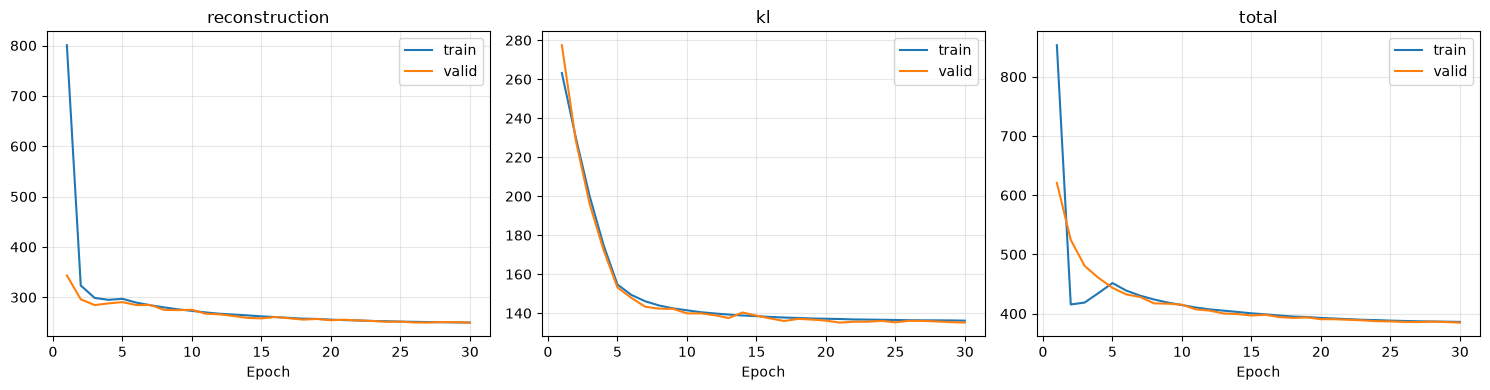

In [6]:
num_epochs_vae = 30
beta = 1.0
optimizer_vae = optim.Adam(vae_model.parameters(), lr=2e-4)
scheduler = optim.lr_scheduler.CosineAnnealingLR(optimizer_vae, num_epochs_vae, eta_min=2e-5)
config = dict(image_size=image_size, crop_size=140, latent_dim=latent_dim_vae,
              epochs=num_epochs_vae, batch_size=batch_size, lr=2e-4,
              beta=beta, warmup_epochs=5, seed=SEED, log_dir=log_dir_vae,
              torch_version=str(torch.__version__), train_size=len(dataset),
              valid_size=len(valid_dataset), test_size=len(test_dataset))
Path('results/config.json').write_text(json.dumps(config, indent=2))
writer_vae.add_text('config', json.dumps(config, indent=2))
fixed_images = x_preview[:16].to(device)
fixed_prior = torch.randn(32, latent_dim_vae, device=device)
amp_enabled = device.type == 'cuda'
history, global_step, best_val = [], 0, float('inf')

def evaluate(loader):
    vae_model.eval()
    sums = torch.zeros(4, device=device)
    with torch.no_grad():
        for x, _ in loader:
            x = x.to(device, non_blocking=True)
            # Фиксируем шум для сопоставимых оценок stochastic ELBO по эпохам.
            with torch.autocast(device_type=device.type, dtype=torch.bfloat16, enabled=amp_enabled):
                xr, mu, logvar, _ = vae_model(x)
            _, rec, kl = vae_loss(xr, x, mu, logvar, beta=1)
            mean_recon = vae_model.decoder(mu.float())
            mean_mse = (mean_recon - x).square().mean()
            sums += torch.stack([rec, kl, mean_mse, rec + kl]) * len(x)
    return (sums / len(loader.dataset)).cpu().tolist()

def save_checkpoint(path, epoch):
    tmp = Path(str(path) + '.tmp')
    torch.save(dict(model_state_dict=vae_model.state_dict(),
                    optimizer_state_dict=optimizer_vae.state_dict(),
                    scheduler_state_dict=scheduler.state_dict(),
                    epoch=epoch, global_step=global_step, config=config,
                    history=history, best_val=best_val,
                    torch_rng_state=torch.get_rng_state(),
                    cuda_rng_states=torch.cuda.get_rng_state_all()), tmp)
    tmp.replace(path)

started = time.time()
print('Начало обучения VAE с нуля...')
for epoch in range(num_epochs_vae):
    epoch_started = time.time()
    vae_model.train()
    epoch_sums = torch.zeros(3, device=device)
    current_beta = beta * min(1.0, (epoch + 1) / config['warmup_epochs'])
    for x, _ in dataloader:
        x = x.to(device, non_blocking=True)
        flip = torch.rand(len(x), device=device) < 0.5
        x[flip] = x[flip].flip(-1)
        optimizer_vae.zero_grad(set_to_none=True)
        with torch.autocast(device_type=device.type, dtype=torch.bfloat16, enabled=amp_enabled):
            xr, mu, logvar, _ = vae_model(x)
        total, rec, kl = vae_loss(xr, x, mu, logvar, current_beta)
        if not torch.isfinite(total):
            raise FloatingPointError(f'Нечисловой loss на шаге {global_step}')
        total.backward()
        nn.utils.clip_grad_norm_(vae_model.parameters(), 1000)
        optimizer_vae.step()
        epoch_sums += torch.stack([total.detach(), rec.detach(), kl.detach()]) * len(x)
        if global_step % 50 == 0:
            for tag, value in zip(['total', 'reconstruction', 'kl'], [total, rec, kl]):
                writer_vae.add_scalar(f'train_step/{tag}', value.item(), global_step)
        global_step += 1
    train_total, train_rec, train_kl = (epoch_sums / len(dataset)).cpu().tolist()
    # fork_rng сохраняет поток случайных чисел обучения.
    with torch.random.fork_rng(devices=[device.index or 0] if amp_enabled else []):
        torch.manual_seed(SEED + 100)
        valid_rec, valid_kl, valid_mse, valid_total = evaluate(valid_loader)
    row = dict(epoch=epoch + 1, beta=current_beta, train_total=train_total,
               train_reconstruction=train_rec, train_kl=train_kl,
               valid_total=valid_total, valid_reconstruction=valid_rec,
               valid_kl=valid_kl, valid_mean_mse=valid_mse,
               lr=optimizer_vae.param_groups[0]['lr'], seconds=time.time() - epoch_started)
    history.append(row)
    for key, value in row.items():
        if key != 'epoch': writer_vae.add_scalar(f'epoch/{key}', value, epoch + 1)
    with torch.no_grad():
        fixed_mu, _ = vae_model.encoder(fixed_images)
        reconstruction = vae_model.decoder(fixed_mu)
        comparison = torch.cat([fixed_images[:8], reconstruction[:8]])
        writer_vae.add_images('images/reconstruction', (comparison + 1) / 2, epoch + 1)
        writer_vae.add_images('images/prior_samples', (vae_model.decoder(fixed_prior) + 1) / 2, epoch + 1)
    scheduler.step()
    # Выбор лучшей модели по validation при полном beta=1 после разогрева.
    if current_beta == beta and valid_total < best_val:
        best_val = valid_total
        save_checkpoint(Path('checkpoints/vae_best.pth'), epoch + 1)
    save_checkpoint(Path('checkpoints/vae_last.pth'), epoch + 1)
    if (epoch + 1) % 5 == 0:
        torch.save(vae_model.state_dict(), f'checkpoints/vae_checkpoint_epoch_{epoch + 1}.pth')
    Path('results/history.json').write_text(json.dumps(history, indent=2))
    writer_vae.flush()
    print(f"Epoch {epoch + 1:02d}/{num_epochs_vae}: train={train_total:.2f} "
          f"(recon={train_rec:.2f}, KL={train_kl:.2f}), valid={valid_total:.2f}, "
          f"MSE(mu)={valid_mse:.5f}, beta={current_beta:.2f}, {row['seconds']:.1f}s", flush=True)

checkpoint = torch.load('checkpoints/vae_best.pth', map_location=device, weights_only=False)
vae_model.load_state_dict(checkpoint['model_state_dict'])
vae_model.eval()
checkpoint['selected_by'] = 'minimum validation reconstruction + KL, beta=1'
torch.save(checkpoint, 'checkpoints/vae_final.pth')
print(f"Готово за {(time.time() - started) / 60:.1f} мин. "
      f"Финальная модель: эпоха {checkpoint['epoch']}, valid={checkpoint['best_val']:.2f}")

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, metric in zip(axes, ['reconstruction', 'kl', 'total']):
    ax.plot([h['epoch'] for h in history], [h[f'train_{metric}'] for h in history], label='train')
    ax.plot([h['epoch'] for h in history], [h[f'valid_{metric}'] for h in history], label='valid')
    ax.set_title(metric); ax.set_xlabel('Epoch'); ax.legend(); ax.grid(alpha=.3)
plt.tight_layout(); plt.savefig('results/learning_curves.png', dpi=150); plt.show()


### Часть A. Шаг 5: Визуализация реконструкций

Что сделать: вывести несколько пар "оригинал - реконструкция" и визуально оценить качество работы модели VAE.

Ожидается: визуально осмысленные реконструкции.

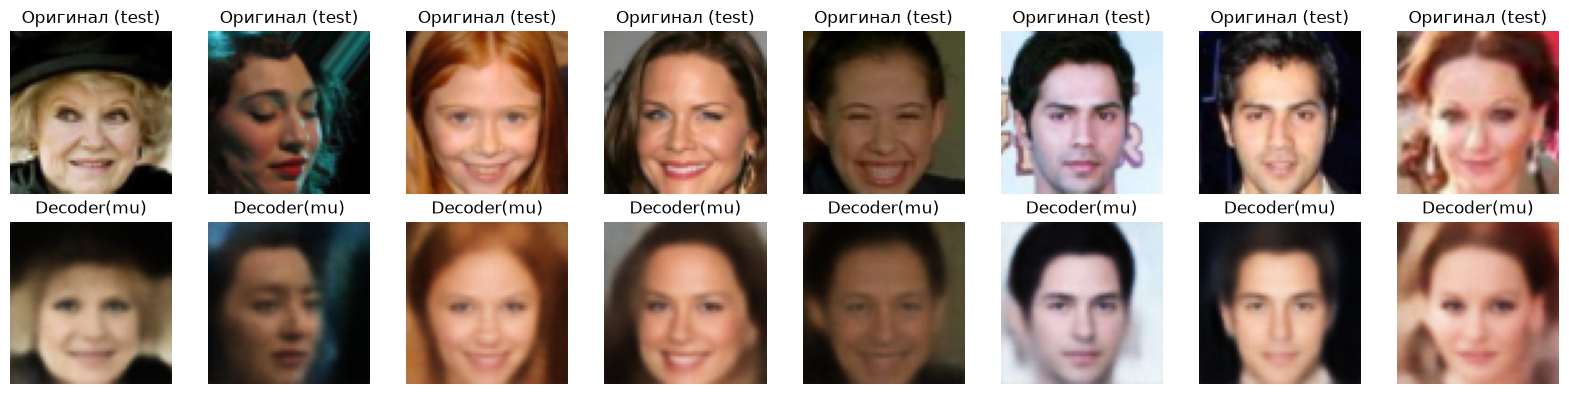

{
  "selected_epoch": 30,
  "test_reconstruction": 247.00006103515625,
  "test_kl": 134.67263793945312,
  "test_elbo_loss": 381.6727294921875,
  "test_mse_mu": 0.016106782481074333,
  "test_psnr_mu": 23.950511976669162,
  "train_minutes": 2.663311743736267
}
PSNR рассчитан после преобразования из [-1,1] в [0,1].


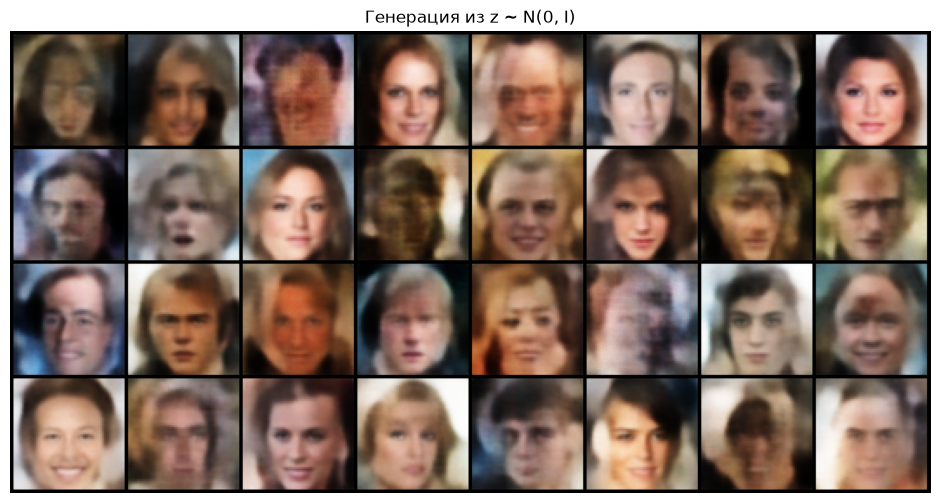

In [7]:
vae_model.eval()
x_batch, attrs_batch = next(iter(test_loader))
x_batch = x_batch[:16].to(device)
with torch.no_grad():
    mu_batch, logvar_batch = vae_model.encoder(x_batch)
    z_batch = vae_model.reparameterize(mu_batch, logvar_batch)
    # Для сравнения и редактирования используем mu без шума.
    x_recon_batch = vae_model.decoder(mu_batch)
assert torch.isfinite(mu_batch).all()
x_vis = ((x_batch + 1) / 2).clamp(0, 1).cpu()
x_recon_vis = ((x_recon_batch + 1) / 2).clamp(0, 1).cpu()
num_show = 8
fig, axes = plt.subplots(2, num_show, figsize=(16, 4))
for i in range(num_show):
    axes[0, i].imshow(x_vis[i].permute(1, 2, 0)); axes[0, i].axis('off'); axes[0, i].set_title('Оригинал (test)')
    axes[1, i].imshow(x_recon_vis[i].permute(1, 2, 0)); axes[1, i].axis('off'); axes[1, i].set_title('Decoder(mu)')
plt.tight_layout(); plt.savefig('results/reconstructions.png', dpi=150); plt.show()
writer_vae.add_images('test/original', x_vis, global_step)
writer_vae.add_images('test/reconstructed_mu', x_recon_vis, global_step)
with torch.random.fork_rng(devices=[device.index or 0] if amp_enabled else []):
    torch.manual_seed(SEED + 100)
    test_rec, test_kl, test_mse, test_total = evaluate(test_loader)
metrics = dict(selected_epoch=checkpoint['epoch'], test_reconstruction=test_rec,
               test_kl=test_kl, test_elbo_loss=test_total, test_mse_mu=test_mse,
               test_psnr_mu=-10 * math.log10(test_mse / 4),
               train_minutes=sum(h['seconds'] for h in history) / 60)
Path('results/metrics.json').write_text(json.dumps(metrics, indent=2))
print(json.dumps(metrics, indent=2))
print('PSNR рассчитан после преобразования из [-1,1] в [0,1].')
with torch.no_grad():
    samples = (vae_model.decoder(fixed_prior) + 1).clamp(0, 2) / 2
save_image(samples, 'results/prior_samples.png', nrow=8)
plt.figure(figsize=(12, 6)); plt.imshow(make_grid(samples.cpu(), nrow=8).permute(1, 2, 0))
plt.axis('off'); plt.title('Генерация из z ~ N(0, I)'); plt.show()


### Часть A. Шаг 6: Редактирование латентного пространства (улыбка → грусть)

Что сделать: использовать атрибут `Smiling` в CelebA для выделения улыбающихся и неулыбающихся лиц, вычислить направление в латентном пространстве и применить его к новым изображениям.

Средние по группам считаем по `mu`, а не по сэмплированному `z`: так в направление не попадает шум сэмплирования.

Ожидается: пары «до/после» с изменением эмоции, логирование результатов в TensorBoard.

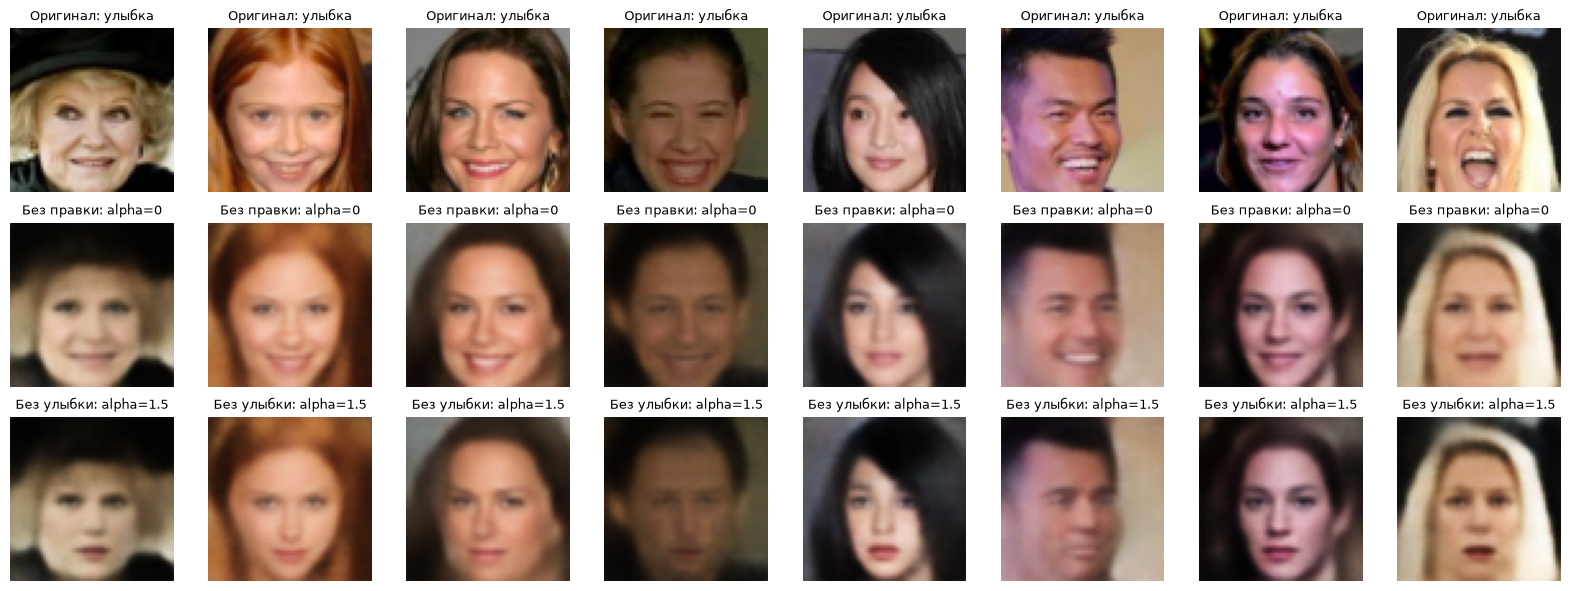

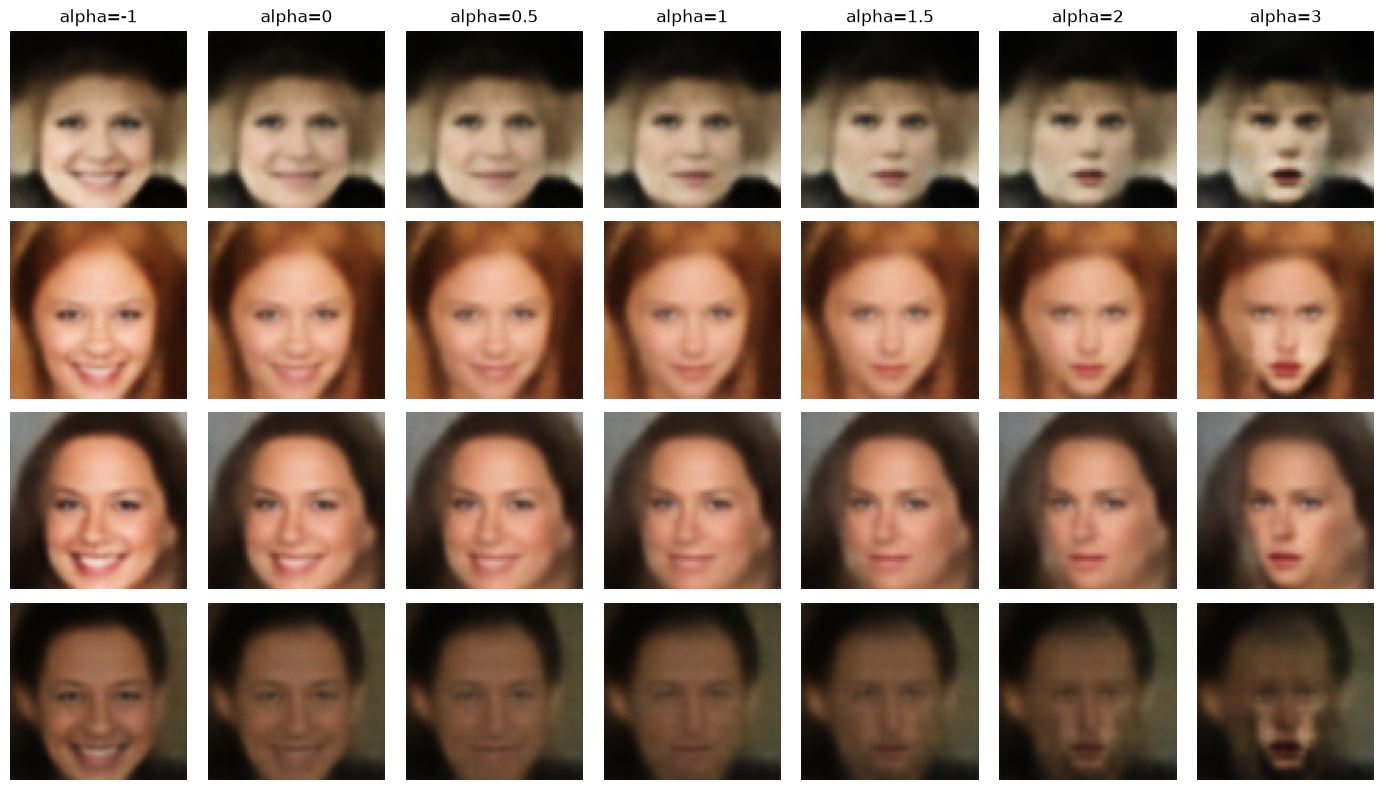

Направление оценено по 5000+5000 train-лицам; norm=1.7316
Латентные векторы mu, z и edited_z сохранены; результаты записаны в TensorBoard.


In [8]:
smile_idx = dataset.attr_names.index('Smiling')
smile_indices = torch.where(dataset.attr[:, smile_idx] == 1)[0]
sad_indices = torch.where(dataset.attr[:, smile_idx] == 0)[0]
rng = torch.Generator().manual_seed(SEED)
N = 5000
smile_indices = smile_indices[torch.randperm(len(smile_indices), generator=rng)[:N]].tolist()
sad_indices = sad_indices[torch.randperm(len(sad_indices), generator=rng)[:N]].tolist()

@torch.inference_mode()
def encode_indices(source, indices):
    loader = DataLoader(Subset(source, indices), batch_size=256, num_workers=4, pin_memory=True)
    vectors = []
    for images, _ in loader:
        mu, _ = vae_model.encoder(images.to(device, non_blocking=True))
        vectors.append(mu.cpu())
    return torch.cat(vectors)

vae_model.eval()
smile_mu = encode_indices(dataset, smile_indices)
sad_mu = encode_indices(dataset, sad_indices)
smile_z_mean = smile_mu.mean(0).to(device)
sad_z_mean = sad_mu.mean(0).to(device)
# Полное расстояние между центрами сохраняет понятный масштаб alpha.
direction = sad_z_mean - smile_z_mean
alpha = 1.5
assert torch.isfinite(direction).all() and direction.norm() > 0

# Только test: эти лица не участвовали ни в обучении, ни в оценке направления.
num_edit = 8
edit_indices = torch.where(test_dataset.attr[:, smile_idx] == 1)[0][:num_edit].tolist()
edit_batch = torch.stack([test_dataset[i][0] for i in edit_indices]).to(device)
with torch.no_grad():
    edit_mu, edit_logvar = vae_model.encoder(edit_batch)
    edited_z = edit_mu + alpha * direction
    base_recon = vae_model.decoder(edit_mu)
    edited_imgs = vae_model.decoder(edited_z)

fig, axes = plt.subplots(3, num_edit, figsize=(16, 6))
for row, (images, title) in enumerate([
    (edit_batch, 'Оригинал: улыбка'), (base_recon, 'Без правки: alpha=0'),
    (edited_imgs, f'Без улыбки: alpha={alpha}')]):
    for i in range(num_edit):
        axes[row, i].imshow(((images[i].detach().cpu() + 1) / 2).clamp(0, 1).permute(1, 2, 0))
        axes[row, i].axis('off'); axes[row, i].set_title(title, fontsize=9)
plt.tight_layout(); plt.savefig('results/emotion_edit.png', dpi=160); plt.show()

alphas = [-1.0, 0.0, 0.5, 1.0, 1.5, 2.0, 3.0]
with torch.no_grad():
    sweep = torch.stack([vae_model.decoder(edit_mu[:4] + a * direction) for a in alphas], dim=1)
fig, axes = plt.subplots(4, len(alphas), figsize=(14, 8))
for i in range(4):
    for j, a in enumerate(alphas):
        axes[i, j].imshow(((sweep[i, j].cpu() + 1) / 2).clamp(0, 1).permute(1, 2, 0))
        axes[i, j].axis('off')
        if i == 0: axes[i, j].set_title(f'alpha={a:g}')
plt.tight_layout(); plt.savefig('results/alpha_sweep.png', dpi=160); plt.show()

for tag, images in [('original', edit_batch), ('baseline_mu', base_recon), ('edited', edited_imgs)]:
    writer_vae.add_images(f'emotion/{tag}', ((images + 1) / 2).clamp(0, 1), global_step)
writer_vae.add_images('emotion/alpha_sweep', ((sweep.flatten(0, 1) + 1) / 2).clamp(0, 1), global_step)
writer_vae.add_scalar('emotion/direction_norm', direction.norm().item(), global_step)
torch.save(dict(direction=direction.cpu(), smile_mean=smile_z_mean.cpu(),
                non_smile_mean=sad_z_mean.cpu(), alpha=alpha,
                edit_mu=edit_mu.cpu(), edited_z=edited_z.cpu(),
                sampled_z=vae_model.reparameterize(edit_mu, edit_logvar).detach().cpu(),
                edit_filenames=[test_dataset.filenames[i] for i in edit_indices],
                reference_smile_filenames=[dataset.filenames[i] for i in smile_indices],
                reference_non_smile_filenames=[dataset.filenames[i] for i in sad_indices],
                reference_split='train', edit_split='test', attribute='Smiling'),
           'checkpoints/emotion_direction.pt')
print(f'Направление оценено по {N}+{N} train-лицам; norm={direction.norm().item():.4f}')
print('Латентные векторы mu, z и edited_z сохранены; результаты записаны в TensorBoard.')


### Часть A. Шаг 7: Текстовое объяснение метода

Что сделать: кратко описать (1–2 абзаца), как вы вычисляли направление smile - sad и как изменение alpha влияет на результат.

Ожидается: понятное описание работы.

Направление редактирования вычислено как **d = mean(mu | Smiling=0) − mean(mu | Smiling=1)**: взяты по 5000 случайных лиц каждой группы только из обучающей выборки. Использованы средние `mu`, а не случайные `z`, поэтому шум reparameterization не искажает направление. Для новых улыбающихся лиц из test получаем `mu_edit = mu + alpha · d` и передаём его в decoder. Строка `alpha=0` показывает обычную реконструкцию: она позволяет отделить изменение от редактирования от ошибки самой VAE. Вместе с итоговыми весами сохранены направление и извлечённые латентные векторы.

При `alpha=0` правки нет, положительное `alpha` сдвигает лицо к группе без улыбки, отрицательное — усиливает улыбку. В показанном примере используется `alpha=1.5`; отдельно выведена шкала от −1 до 3, чтобы увидеть силу эффекта и сопутствующие изменения. Слишком большой сдвиг может менять идентичность и давать артефакты: среднее направление не отделяет эмоцию от коррелирующих признаков. В CelebA нет метки «грусть», поэтому здесь реализован переход «улыбка → отсутствие улыбки» как приближение к формулировке задания. VAE с пиксельным MSE также склонна сглаживать мелкие детали.


**Полученные результаты.** Выполнены все 30 эпох на 162 770 обучающих изображениях; выбрана эпоха 30. Validation loss снизился с 620.90 до 384.86. На отложенном test: loss=381.67, PSNR для decoder(mu)=23.95 dB. На примерах test при alpha=1.5 улыбка ослабевает; при alpha=3 видны более сильные сопутствующие изменения формы рта. Мелкие детали реконструкций сглажены.


In [9]:
writer_vae.add_text('conclusion', 'Направление non-smile − smile оценено по train mu; редактирование на test. Smiling=0 не является меткой грусти.', global_step)
writer_vae.flush()
writer_vae.close()
from tensorboard.backend.event_processing.event_accumulator import EventAccumulator
acc = EventAccumulator(log_dir_vae, size_guidance={'images': 1})
acc.Reload()
print('TensorBoard scalar tags:', acc.Tags()['scalars'])
print('TensorBoard image tags:', acc.Tags()['images'])
assert len(acc.Scalars('epoch/valid_total')) == num_epochs_vae
assert 'emotion/edited' in acc.Tags()['images']
assert acc.Tags()['graph']
assert all(Path(p).is_file() for p in [
    'checkpoints/vae_final.pth', 'checkpoints/emotion_direction.pt',
    'results/reconstructions.png', 'results/emotion_edit.png', 'results/alpha_sweep.png'])
# Повторная загрузка checkpoint и воспроизводимость детерминированной реконструкции.
restored = VAE(latent_dim_vae).to(device)
saved = torch.load('checkpoints/vae_final.pth', map_location=device, weights_only=False)
restored.load_state_dict(saved['model_state_dict'])
restored.eval()
with torch.no_grad():
    restored_mu, _ = restored.encoder(edit_batch)
    assert torch.allclose(restored.decoder(restored_mu), base_recon, atol=1e-6)
del restored
print('Проверены итоговые веса, латентные векторы и TensorBoard. Ноутбук выполнен полностью.')


TensorBoard scalar tags: ['train_step/total', 'train_step/reconstruction', 'train_step/kl', 'epoch/beta', 'epoch/train_total', 'epoch/train_reconstruction', 'epoch/train_kl', 'epoch/valid_total', 'epoch/valid_reconstruction', 'epoch/valid_kl', 'epoch/valid_mean_mse', 'epoch/lr', 'epoch/seconds', 'emotion/direction_norm']
TensorBoard image tags: ['images/reconstruction', 'images/prior_samples', 'test/original', 'test/reconstructed_mu', 'emotion/original', 'emotion/baseline_mu', 'emotion/edited', 'emotion/alpha_sweep']
Проверены итоговые веса, латентные векторы и TensorBoard. Ноутбук выполнен полностью.
